#### imports

In [4]:
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torch
import random

#### getting Data

In [5]:
words = open('../names.txt', 'r').read().splitlines()

In [6]:
letters = sorted(list(set(''.join(words))))
str_to_int = {s:i+1 for i, s in enumerate(letters)}
str_to_int['.'] = 0
int_to_str = {i:s for s, i in str_to_int.items()}
vocab_size = len(int_to_str)

In [7]:
context_length = 3

def build_dataset(words):
    X, Y = [], []

    for word in words:
        context = [0] * context_length
        for character in word + '.':
            index = str_to_int[character]
            Y.append(index)
            X.append(context)
            context = context[1:] + [index]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y


random.seed(1234)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtrain, Ytrain = build_dataset(words[:n1])
Xval, Yval = build_dataset(words[n1:n2])
Xtest, Ytest = build_dataset(words[n2:])


#### Parameters

In [10]:
embedded_dim = 10
n_hidden = 200

g = torch.Generator().manual_seed(6710)
C = torch.randn((vocab_size,embedded_dim),                  generator=g)
W1 = torch.randn((context_length * embedded_dim, n_hidden), generator=g) * (5/3) / (context_length * embedded_dim)**0.5
W2 = torch.randn((n_hidden, vocab_size),                    generator=g) * 0.01
b2 = torch.rand(27,                                         generator=g) * 0
bn_gain = torch.ones(1, n_hidden)
bn_bias = torch.zeros(1, n_hidden)

bn_mean_running = torch.zeros(1, n_hidden)
bn_std_running = torch.ones(1, n_hidden)

parameters = [C, W1, W2, b2, bn_gain, bn_bias]

for p in parameters:
    p.requires_grad=True

#### Checking Loss at initialisation

In [17]:
-torch.tensor(1/27).log() #(at initialisation weights shld be roughly this)

tensor(3.2958)

In [14]:
with torch.no_grad():
    emb_concat = C[Xtrain[:32]].view(32, -1)
    h_pre = emb_concat @ W1
    h_pre = bn_gain * (h_pre - h_pre.mean(0, keepdim=True)) / h_pre.std(0, keepdim=True) + bn_bias
    h = torch.tanh(h_pre)
    loss = F.cross_entropy(h @ W2 + b2, Ytrain[:32])
print(loss)

tensor(3.2996)


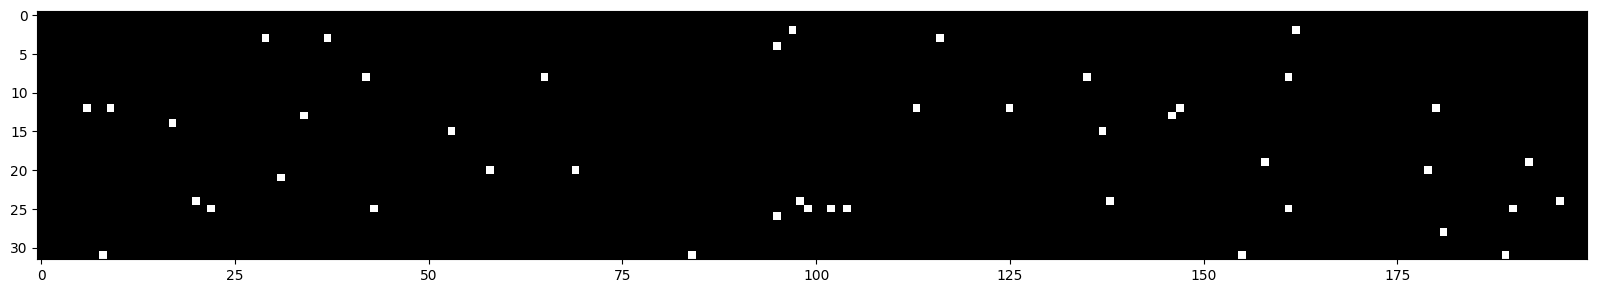

In [15]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99,cmap = 'gray', interpolation = 'nearest')

#### Training MLP

In [16]:
max_steps = 200_000
batch_size = 32
loss_list = []

for k in range(max_steps):

    #minibatch
    index = torch.randint(0, Xtrain.shape[0], (batch_size,) , generator=g)

    # Forward
    embeddings = C[Xtrain[index]]
    emb_concat = embeddings.view(embeddings.shape[0], -1)
    h_pre_activation =  emb_concat @ W1 #b1 useless due to normalisation

    bn_mean_current = h_pre_activation.mean(axis=0, keepdim = True)
    bn_std_current = h_pre_activation.std(axis=0, keepdim = True)

    with torch.no_grad():
        bn_mean_running = 0.999 * bn_mean_running + 0.001 * bn_mean_current
        bn_std_running = 0.999 * bn_std_running + 0.001 * bn_std_current

    h_pre_activation = bn_gain * ((h_pre_activation - bn_mean_current) / bn_std_current) + bn_bias
    h = torch.tanh(h_pre_activation)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytrain[index])
 
    #Backward
    for p in parameters:
        p.grad = None
    loss.backward()

    #Update
    step_size = 0.1 if k < 100_000 else 0.01
    for p in parameters:
        p.data += -step_size * p.grad

    #tracking
    if k % 10_000 == 0:
        print(f"{k:7d}/{max_steps:7d}: {loss.item():.4f}")
    loss_list.append(loss.log10().item())


      0/ 200000: 3.3072
  10000/ 200000: 1.8899
  20000/ 200000: 2.1231
  30000/ 200000: 2.0116
  40000/ 200000: 2.3384
  50000/ 200000: 2.0069
  60000/ 200000: 1.9463
  70000/ 200000: 2.1667
  80000/ 200000: 2.0607
  90000/ 200000: 1.6687
 100000/ 200000: 2.5278
 110000/ 200000: 2.1179
 120000/ 200000: 1.9494
 130000/ 200000: 2.0905
 140000/ 200000: 2.1387
 150000/ 200000: 1.9636
 160000/ 200000: 2.1628
 170000/ 200000: 2.0449
 180000/ 200000: 2.5691
 190000/ 200000: 2.0889


#### plotting loss

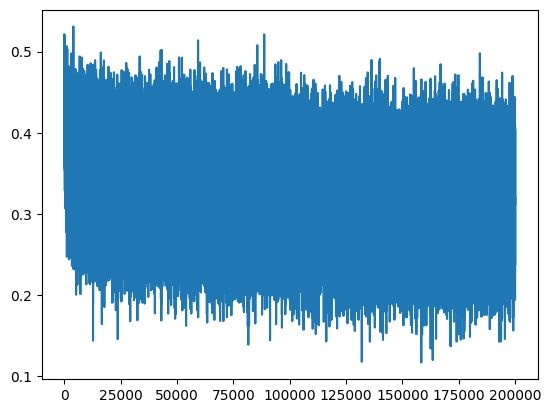

In [18]:
plt.plot(loss_list)

#### evaluating MLP

In [21]:
@torch.no_grad()  # only evaluating, so no gradients needed
def split_loss(split):
    x, y = {
        'train': (Xtrain, Ytrain),
        'val':   (Xval, Yval),
        'test':  (Xtest, Ytest),
    }[split]

    emb_concat = C[x].view(x.shape[0], -1)
    h_pre = emb_concat @ W1
    h_pre = bn_gain * (h_pre - bn_mean_running) / (bn_std_running + 1e-5) + bn_bias  # batchnorm with running stats
    h = torch.tanh(h_pre)
    logits = h @ W2 + b2
    print(split, f"{F.cross_entropy(logits, y).item():.4f}")

split_loss('train')
split_loss('val')

train 2.0670
val 2.1152


#### generating from MLP

In [25]:
g = torch.Generator().manual_seed(6710 + 10)

for i in range(10):
    out = []
    context = [0] * context_length
    while True:
        emb_concat = C[context].view(1, -1)  # 1 example at a time
        h_pre = emb_concat @ W1
        h_pre = bn_gain * (h_pre - bn_mean_running) / (bn_std_running + 1e-5) + bn_bias  # batchnorm with running stats
        h = torch.tanh(h_pre)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        index = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [index]
        out.append(index)
        if index == 0:
            break
    print(''.join(int_to_str[i] for i in out))

teyas.
kaia.
elleyah.
cha.
majeshalanilelle.
gabmarvius.
amik.
ara.
elin.
kion.
